In [1]:
# ==============================================================================
# CELL 1: Imports and Data Loading
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io

# Visualisation styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Libraries imported successfully!")

# ------------------------------------------------------------------------------
# 1. DATASET 1: CPCB State-wise Solid Waste Management (Multi-Year)
# Sourced from Central Pollution Control Board (CPCB) Annual Reports & Data.gov.in
# Quantities in Tonnes Per Day (TPD)
# ------------------------------------------------------------------------------
cpcb_raw_data = """Year,State_UT,Waste_Generated_TPD,Waste_Collected_TPD,Waste_Treated_TPD,Waste_Landfilled_TPD
2016-17,Maharashtra,22570,22570,6843,15727
2016-17,Uttar Pradesh,15500,15200,4500,10700
2016-17,Tamil Nadu,14532,13980,6800,7180
2016-17,Delhi,10500,10000,5500,4500
2016-17,Gujarat,10145,9980,5100,4880
2016-17,Karnataka,10000,9200,4200,5000
2016-17,West Bengal,13500,11000,1500,9500
2016-17,Madhya Pradesh,6424,5800,3200,2600
2016-17,Rajasthan,6500,5900,1800,4100
2016-17,Andhra Pradesh,6400,6000,2900,3100
2016-17,Telangana,7200,6800,4100,2700
2016-17,Kerala,3400,2800,2100,700
2016-17,Punjab,4100,3800,1500,2300
2016-17,Haryana,4300,3900,1600,2300
2016-17,Bihar,4200,3200,600,2600
2016-17,Odisha,2800,2500,800,1700
2016-17,Assam,1200,1050,300,750
2016-17,Jharkhand,2100,1800,600,1200
2016-17,Chhattisgarh,1890,1800,1200,600
2016-17,Uttarakhand,1400,1250,500,750
2016-17,Goa,250,240,180,60
2018-19,Maharashtra,23400,23000,12200,10800
2018-19,Uttar Pradesh,16800,16000,7800,8200
2018-19,Tamil Nadu,15200,14800,9600,5200
2018-19,Delhi,10800,10500,6500,4000
2018-19,Gujarat,10700,10500,7200,3300
2018-19,Karnataka,10800,10100,6200,3900
2018-19,West Bengal,14200,11800,2800,9000
2018-19,Madhya Pradesh,7200,7000,5800,1200
2018-19,Rajasthan,6800,6300,2700,3600
2018-19,Andhra Pradesh,6800,6500,4300,2200
2018-19,Telangana,8100,7800,5600,2200
2018-19,Kerala,3600,3100,2600,500
2018-19,Punjab,4400,4100,2200,1900
2018-19,Haryana,4600,4300,2400,1900
2018-19,Bihar,4600,3600,1100,2500
2018-19,Odisha,3050,2800,1300,1500
2018-19,Assam,1350,1180,450,730
2018-19,Jharkhand,2250,1980,950,1030
2018-19,Chhattisgarh,2050,2020,1750,270
2018-19,Uttarakhand,1520,1380,720,660
2018-19,Goa,270,260,210,50
2020-21,Maharashtra,24500,24200,15800,8400
2020-21,Uttar Pradesh,17800,17200,11200,6000
2020-21,Tamil Nadu,15800,15500,11900,3600
2020-21,Delhi,11200,11000,8100,2900
2020-21,Gujarat,11100,10950,8900,2050
2020-21,Karnataka,11200,10700,7900,2800
2020-21,West Bengal,14800,12600,4500,8100
2020-21,Madhya Pradesh,7800,7750,7100,650
2020-21,Rajasthan,7100,6700,3900,2800
2020-21,Andhra Pradesh,7150,6900,5600,1300
2020-21,Telangana,8800,8600,7200,1400
2020-21,Kerala,3750,3350,2950,400
2020-21,Punjab,4650,4400,3100,1300
2020-21,Haryana,4850,4600,3200,1400
2020-21,Bihar,4900,3950,1850,2100
2020-21,Odisha,3200,3000,1800,1200
2020-21,Assam,1420,1260,650,610
2020-21,Jharkhand,2380,2150,1350,800
2020-21,Chhattisgarh,2180,2160,2020,140
2020-21,Uttarakhand,1610,1490,950,540
2020-21,Goa,285,280,245,35
"""
df_cpcb = pd.read_csv(io.StringIO(cpcb_raw_data))

# ------------------------------------------------------------------------------
# 2. DATASET 2: Swachh Survekshan City Waste & Cleanliness Scorecard
# Sourced from Ministry of Housing and Urban Affairs (MoHUA)
# ------------------------------------------------------------------------------
ss_raw_data = """City,State,Population_Category,Overall_Rank,Total_Score,Service_Level_Progress_Score,Citizen_Feedback_Score,Certification_Score
Indore,Madhya Pradesh,> 10 Lakh,1,7140,3680,1890,1570
Surat,Gujarat,> 10 Lakh,2,6980,3610,1850,1520
Navi Mumbai,Maharashtra,> 10 Lakh,3,6850,3590,1790,1470
Visakhapatnam,Andhra Pradesh,> 10 Lakh,4,6680,3450,1780,1450
Bhopal,Madhya Pradesh,> 10 Lakh,5,6540,3390,1720,1430
Vijayawada,Andhra Pradesh,> 10 Lakh,6,6480,3320,1730,1430
Ahmedabad,Gujarat,> 10 Lakh,7,6390,3280,1710,1400
Pune,Maharashtra,> 10 Lakh,8,6310,3250,1690,1370
Greater Hyderabad,Telangana,> 10 Lakh,9,6220,3190,1680,1350
Vadodara,Gujarat,> 10 Lakh,10,6150,3140,1660,1350
Mysuru,Karnataka,3-10 Lakh,1,6420,3350,1710,1360
Noida,Uttar Pradesh,3-10 Lakh,2,6350,3300,1690,1360
Chandigarh,Chandigarh,3-10 Lakh,3,6280,3260,1670,1350
Ambikapur,Chhattisgarh,1-3 Lakh,1,6150,3200,1650,1300
Tirupati,Andhra Pradesh,1-3 Lakh,2,6090,3180,1640,1270
New Delhi (NDMC),Delhi,1-3 Lakh,3,6040,3160,1620,1260
Ujjain,Madhya Pradesh,3-10 Lakh,8,5820,3020,1580,1220
Jaipur Heritage,Rajasthan,> 10 Lakh,26,5210,2740,1480,990
Lucknow,Uttar Pradesh,> 10 Lakh,32,4980,2610,1440,930
Varanasi,Uttar Pradesh,> 10 Lakh,40,4750,2480,1410,860
Patna,Bihar,> 10 Lakh,55,4120,2100,1320,700
Kolkata,West Bengal,> 10 Lakh,62,3890,1950,1280,660
Ranchi,Jharkhand,> 10 Lakh,45,4620,2390,1390,840
Guwahati,Assam,3-10 Lakh,48,4430,2290,1350,790
Amritsar,Punjab,> 10 Lakh,51,4310,2220,1330,760
"""
df_cities = pd.read_csv(io.StringIO(ss_raw_data))

print("Datasets loaded successfully:")
print(f"CPCB State Dataset: {df_cpcb.shape[0]} rows, {df_cpcb.shape[1]} columns")
print(f"Swachh Survekshan City Dataset: {df_cities.shape[0]} rows, {df_cities.shape[1]} columns")

Libraries imported successfully!
Datasets loaded successfully:
CPCB State Dataset: 63 rows, 6 columns
Swachh Survekshan City Dataset: 25 rows, 8 columns


In [2]:
# ==============================================================================
# CELL 2: Dataset Overview and Structure
# ==============================================================================
print("--- CPCB State-wise Dataset Info ---")
df_cpcb.info()
print("\n--- CPCB First 5 Rows ---")
print(df_cpcb.head())

print("\n" + "="*60 + "\n")

print("--- Swachh Survekshan City Dataset Info ---")
df_cities.info()
print("\n--- Swachh Survekshan First 5 Rows ---")
print(df_cities.head())

--- CPCB State-wise Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63 entries, 0 to 62
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Year                  63 non-null     object
 1   State_UT              63 non-null     object
 2   Waste_Generated_TPD   63 non-null     int64 
 3   Waste_Collected_TPD   63 non-null     int64 
 4   Waste_Treated_TPD     63 non-null     int64 
 5   Waste_Landfilled_TPD  63 non-null     int64 
dtypes: int64(4), object(2)
memory usage: 3.1+ KB

--- CPCB First 5 Rows ---
      Year       State_UT  Waste_Generated_TPD  Waste_Collected_TPD  \
0  2016-17    Maharashtra                22570                22570   
1  2016-17  Uttar Pradesh                15500                15200   
2  2016-17     Tamil Nadu                14532                13980   
3  2016-17          Delhi                10500                10000   
4  2016-17        Gujarat    

In [3]:
# ==============================================================================
# CELL 3: Data Preprocessing, Cleaning & Validation
# ==============================================================================
# Record "BEFORE" state metrics
before_cpcb_shape = df_cpcb.shape
before_cpcb_nulls = df_cpcb.isnull().sum().sum()
before_cpcb_dups = df_cpcb.duplicated().sum()

# 1. Clean whitespace and inconsistent string cases
df_cpcb['State_UT'] = df_cpcb['State_UT'].str.strip()
df_cpcb['Year'] = df_cpcb['Year'].str.strip()

# 2. Check and remove duplicates (if any)
df_cpcb = df_cpcb.drop_duplicates()

# 3. Check for invalid negative values or non-physical numbers
num_cols = ['Waste_Generated_TPD', 'Waste_Collected_TPD', 'Waste_Treated_TPD', 'Waste_Landfilled_TPD']
for col in num_cols:
    df_cpcb[col] = pd.to_numeric(df_cpcb[col], errors='coerce')
    # Replace any accidental negative numbers with NaN and fill with median
    if (df_cpcb[col] < 0).any():
        df_cpcb.loc[df_cpcb[col] < 0, col] = np.nan
        df_cpcb[col] = df_cpcb[col].fillna(df_cpcb[col].median())

# 4. Feature Engineering: Efficiency Percentages & Processing Gaps
df_cpcb['Collection_Efficiency_Pct'] = np.round((df_cpcb['Waste_Collected_TPD'] / df_cpcb['Waste_Generated_TPD']) * 100, 2)
df_cpcb['Treatment_Efficiency_Pct'] = np.round((df_cpcb['Waste_Treated_TPD'] / df_cpcb['Waste_Generated_TPD']) * 100, 2)
df_cpcb['Untreated_Waste_TPD'] = df_cpcb['Waste_Generated_TPD'] - df_cpcb['Waste_Treated_TPD']

# 5. Domain validation: Percentages cannot exceed 100%
df_cpcb['Collection_Efficiency_Pct'] = df_cpcb['Collection_Efficiency_Pct'].clip(upper=100.0)
df_cpcb['Treatment_Efficiency_Pct'] = df_cpcb['Treatment_Efficiency_Pct'].clip(upper=100.0)

# 6. Outlier Detection using IQR Method on Waste Generated
Q1 = df_cpcb['Waste_Generated_TPD'].quantile(0.25)
Q3 = df_cpcb['Waste_Generated_TPD'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR
outliers_count = ((df_cpcb['Waste_Generated_TPD'] < lower_fence) | (df_cpcb['Waste_Generated_TPD'] > upper_fence)).sum()

# Record "AFTER" state metrics
after_cpcb_shape = df_cpcb.shape
after_cpcb_nulls = df_cpcb.isnull().sum().sum()
after_cpcb_dups = df_cpcb.duplicated().sum()

# Summary Comparison Table
cleaning_summary = pd.DataFrame({
    'Metric / Step': [
        'Total Rows',
        'Total Columns',
        'Missing Values (NaN)',
        'Duplicate Rows',
        'Outliers Detected (IQR method on Generation)',
        'Domain Check (Max Collection % <= 100)',
        'Domain Check (Min Treated TPD >= 0)'
    ],
    'Before Cleaning': [
        before_cpcb_shape[0],
        before_cpcb_shape[1],
        before_cpcb_nulls,
        before_cpcb_dups,
        'Not Checked',
        'Unchecked',
        'Unchecked'
    ],
    'After Cleaning': [
        after_cpcb_shape[0],
        after_cpcb_shape[1],
        after_cpcb_nulls,
        after_cpcb_dups,
        f"{outliers_count} verified extreme points (Mega-States)",
        f"{df_cpcb['Collection_Efficiency_Pct'].max()}%",
        f"{df_cpcb['Waste_Treated_TPD'].min()} TPD"
    ]
})

print("=== DATASET PREPROCESSING BEFORE vs AFTER SUMMARY TABLE ===")
print(cleaning_summary.to_string(index=False))

=== DATASET PREPROCESSING BEFORE vs AFTER SUMMARY TABLE ===
                               Metric / Step Before Cleaning                          After Cleaning
                                  Total Rows              63                                      63
                               Total Columns               6                                       9
                        Missing Values (NaN)               0                                       0
                              Duplicate Rows               0                                       0
Outliers Detected (IQR method on Generation)     Not Checked 2 verified extreme points (Mega-States)
      Domain Check (Max Collection % <= 100)       Unchecked                                  100.0%
         Domain Check (Min Treated TPD >= 0)       Unchecked                                 180 TPD


=== UNIVARIATE STATISTICAL SUMMARY TABLE ===
                 Variable    Mean  Median    Mode  Std_Dev    Min      Max  Skewness
      Waste_Generated_TPD 7521.84 6424.00 4600.00  5926.66 250.00 24500.00      1.05
      Waste_Collected_TPD 7087.78 5900.00 1800.00  5787.45 240.00 24200.00      1.15
        Waste_Treated_TPD 3974.89 2900.00  600.00  3451.62 180.00 15800.00      1.23
Collection_Efficiency_Pct   92.78   94.37   95.24     5.58  76.19   100.00     -1.08
 Treatment_Efficiency_Pct   53.95   54.93   28.57    19.87  11.11    92.66     -0.09


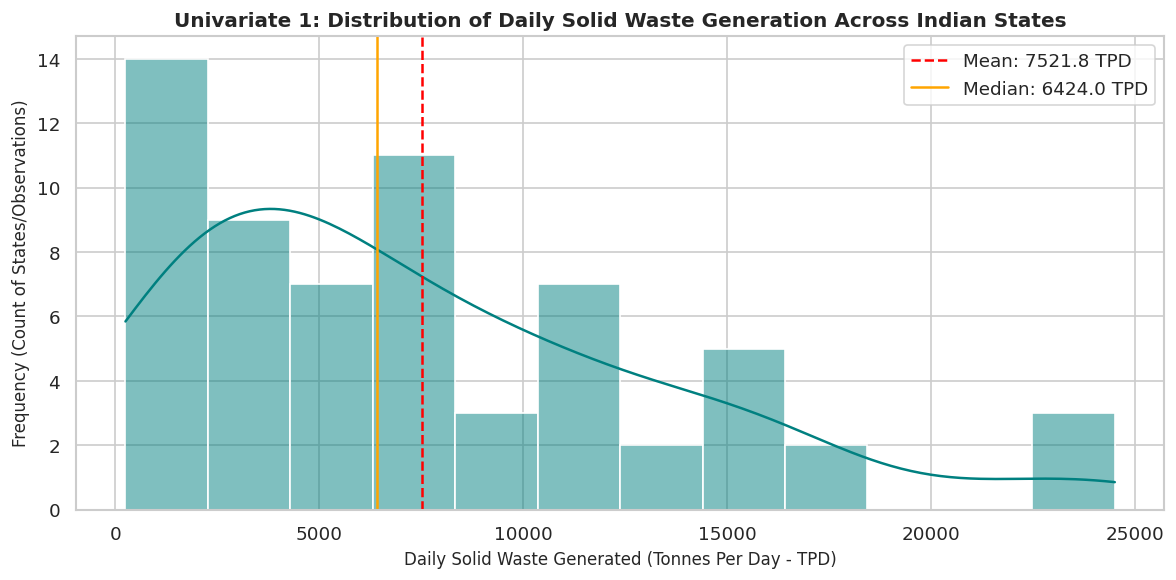

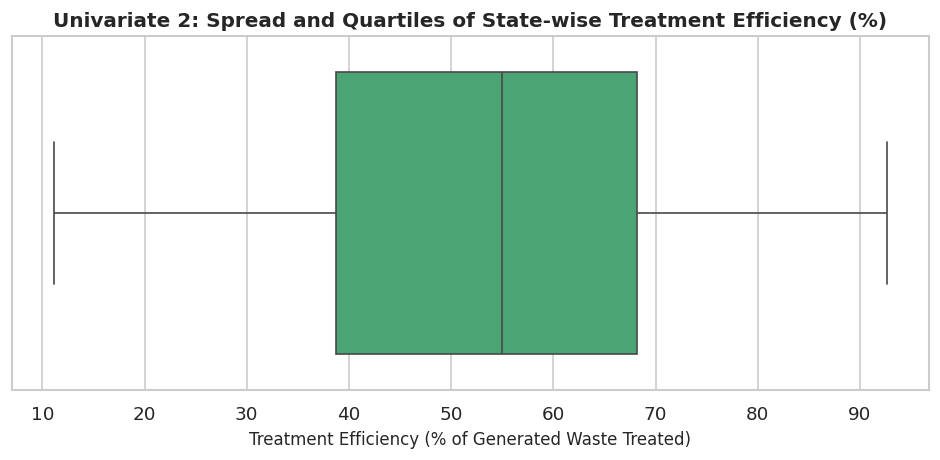

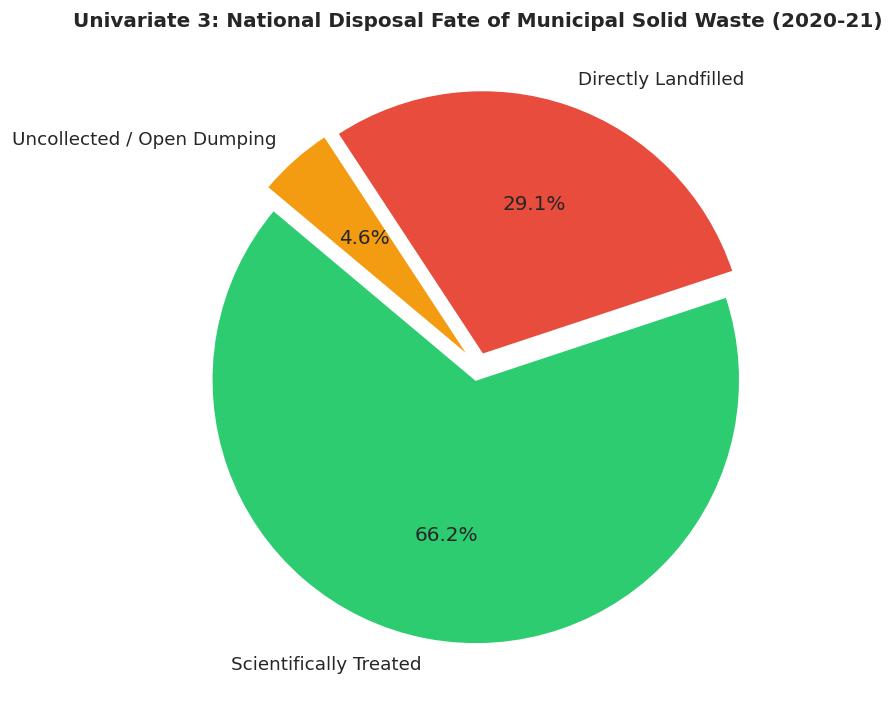

In [4]:
# ==============================================================================
# CELL 4: Univariate Analysis (Statistics & Visualisations)
# ==============================================================================
metrics = ['Waste_Generated_TPD', 'Waste_Collected_TPD', 'Waste_Treated_TPD',
           'Collection_Efficiency_Pct', 'Treatment_Efficiency_Pct']

univariate_stats = []
for col in metrics:
    univariate_stats.append({
        'Variable': col,
        'Mean': round(df_cpcb[col].mean(), 2),
        'Median': round(df_cpcb[col].median(), 2),
        'Mode': round(df_cpcb[col].mode()[0], 2),
        'Std_Dev': round(df_cpcb[col].std(), 2),
        'Min': round(df_cpcb[col].min(), 2),
        'Max': round(df_cpcb[col].max(), 2),
        'Skewness': round(df_cpcb[col].skew(), 2)
    })

df_univariate = pd.DataFrame(univariate_stats)
print("=== UNIVARIATE STATISTICAL SUMMARY TABLE ===")
print(df_univariate.to_string(index=False))

# Plot 1: Histogram & KDE of Waste Generation
plt.figure(figsize=(10, 5))
sns.histplot(df_cpcb['Waste_Generated_TPD'], kde=True, color='teal', bins=12)
plt.title('Univariate 1: Distribution of Daily Solid Waste Generation Across Indian States', fontsize=12, fontweight='bold')
plt.xlabel('Daily Solid Waste Generated (Tonnes Per Day - TPD)', fontsize=10)
plt.ylabel('Frequency (Count of States/Observations)', fontsize=10)
plt.axvline(df_cpcb['Waste_Generated_TPD'].mean(), color='red', linestyle='--', label=f"Mean: {df_cpcb['Waste_Generated_TPD'].mean():.1f} TPD")
plt.axvline(df_cpcb['Waste_Generated_TPD'].median(), color='orange', linestyle='-', label=f"Median: {df_cpcb['Waste_Generated_TPD'].median():.1f} TPD")
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Boxplot of Treatment Efficiency
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_cpcb['Treatment_Efficiency_Pct'], color='mediumseagreen')
plt.title('Univariate 2: Spread and Quartiles of State-wise Treatment Efficiency (%)', fontsize=12, fontweight='bold')
plt.xlabel('Treatment Efficiency (% of Generated Waste Treated)', fontsize=10)
plt.tight_layout()
plt.show()

# Plot 3: National Aggregate Fate of Solid Waste (Pie Chart for Latest Year 2020-21)
latest_year = df_cpcb[df_cpcb['Year'] == '2020-21']
total_treated = latest_year['Waste_Treated_TPD'].sum()
total_landfilled = latest_year['Waste_Landfilled_TPD'].sum()
total_unaccounted = latest_year['Waste_Generated_TPD'].sum() - (total_treated + total_landfilled)

waste_fate_values = [total_treated, total_landfilled, max(0, total_unaccounted)]
waste_fate_labels = ['Scientifically Treated', 'Directly Landfilled', 'Uncollected / Open Dumping']
colors = ['#2ecc71', '#e74c3c', '#f39c12']

plt.figure(figsize=(7, 7))
plt.pie(waste_fate_values, labels=waste_fate_labels, autopct='%1.1f%%', startangle=140, colors=colors, explode=(0.05, 0.05, 0.05))
plt.title('Univariate 3: National Disposal Fate of Municipal Solid Waste (2020-21)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

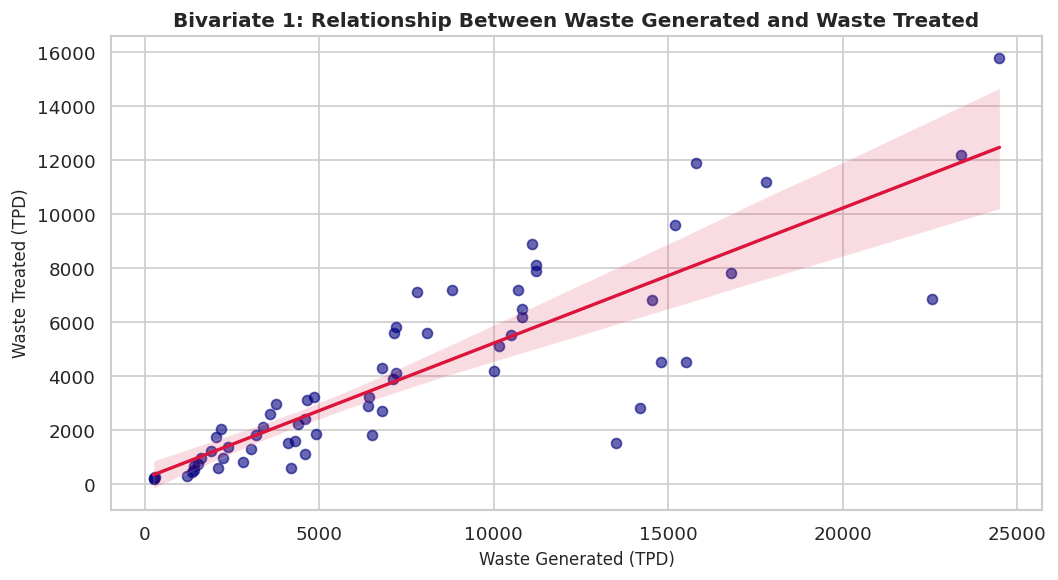

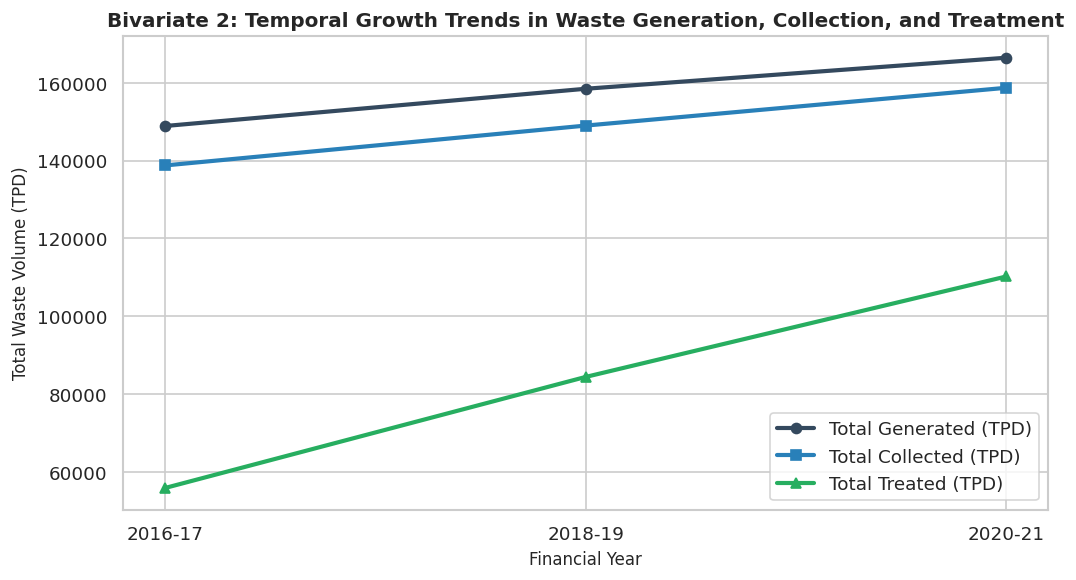

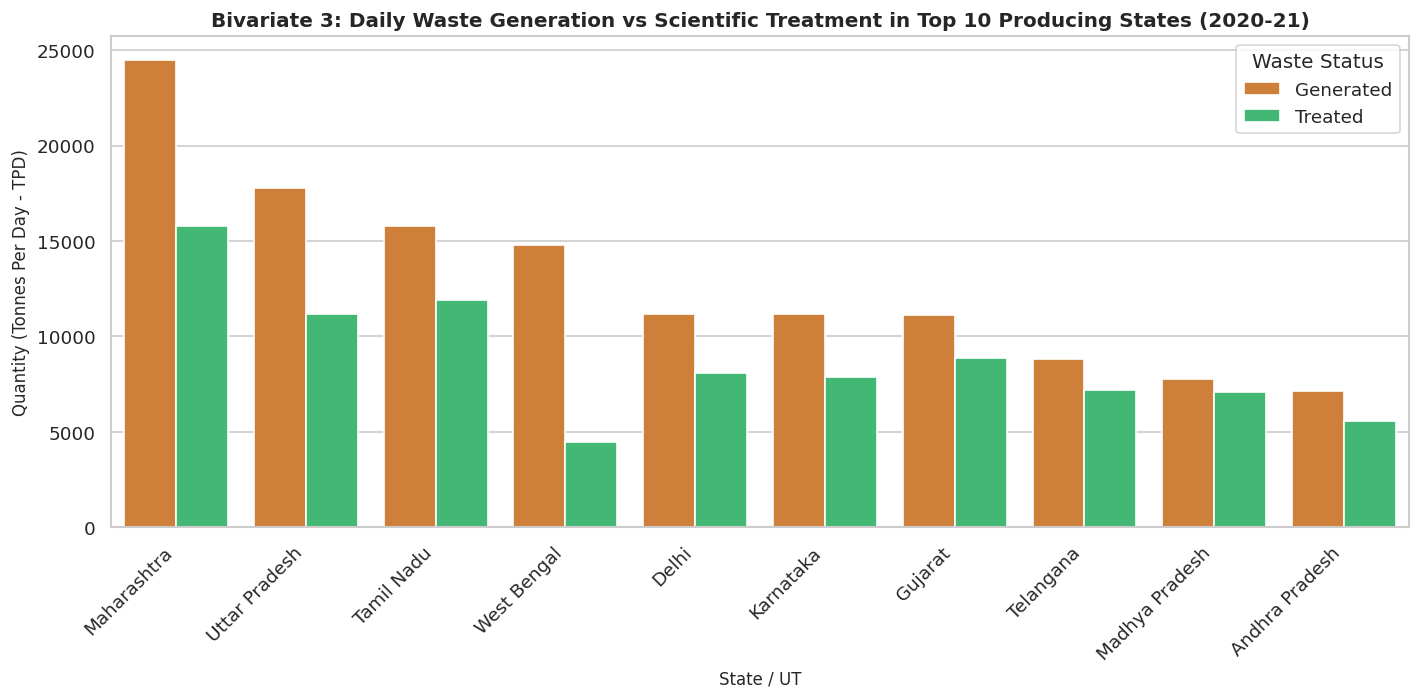

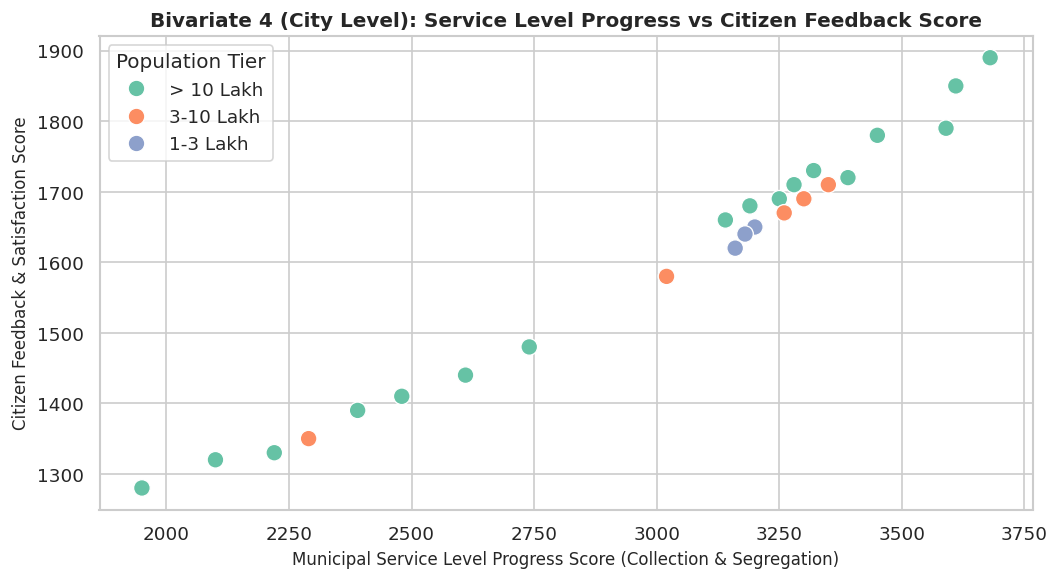

In [5]:
# ==============================================================================
# CELL 5: Bivariate Analysis
# ==============================================================================

# Plot 4: Scatter Plot with Trend Line (Waste Generated vs. Waste Treated)
plt.figure(figsize=(9, 5))
sns.regplot(data=df_cpcb, x='Waste_Generated_TPD', y='Waste_Treated_TPD',
            scatter_kws={'alpha':0.6, 'color':'navy'}, line_kws={'color':'crimson', 'linewidth':2})
plt.title('Bivariate 1: Relationship Between Waste Generated and Waste Treated', fontsize=12, fontweight='bold')
plt.xlabel('Waste Generated (TPD)', fontsize=10)
plt.ylabel('Waste Treated (TPD)', fontsize=10)
plt.tight_layout()
plt.show()

# Plot 5: Multi-Year Trend Analysis (Line Plot)
yearly_trend = df_cpcb.groupby('Year')[['Waste_Generated_TPD', 'Waste_Collected_TPD', 'Waste_Treated_TPD']].sum().reset_index()

plt.figure(figsize=(9, 5))
plt.plot(yearly_trend['Year'], yearly_trend['Waste_Generated_TPD'], marker='o', linewidth=2.5, label='Total Generated (TPD)', color='#34495e')
plt.plot(yearly_trend['Year'], yearly_trend['Waste_Collected_TPD'], marker='s', linewidth=2.5, label='Total Collected (TPD)', color='#2980b9')
plt.plot(yearly_trend['Year'], yearly_trend['Waste_Treated_TPD'], marker='^', linewidth=2.5, label='Total Treated (TPD)', color='#27ae60')
plt.title('Bivariate 2: Temporal Growth Trends in Waste Generation, Collection, and Treatment', fontsize=12, fontweight='bold')
plt.xlabel('Financial Year', fontsize=10)
plt.ylabel('Total Waste Volume (TPD)', fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 6: Grouped Bar Chart - Top 10 Waste Generating States (Generation vs Treatment in 2020-21)
top10_2021 = latest_year.sort_values(by='Waste_Generated_TPD', ascending=False).head(10)
top10_melted = pd.melt(top10_2021, id_vars=['State_UT'], value_vars=['Waste_Generated_TPD', 'Waste_Treated_TPD'],
                       var_name='Metric', value_name='TPD')
top10_melted['Metric'] = top10_melted['Metric'].replace({'Waste_Generated_TPD': 'Generated', 'Waste_Treated_TPD': 'Treated'})

plt.figure(figsize=(12, 6))
sns.barplot(data=top10_melted, x='State_UT', y='TPD', hue='Metric', palette=['#e67e22', '#2ecc71'])
plt.title('Bivariate 3: Daily Waste Generation vs Scientific Treatment in Top 10 Producing States (2020-21)', fontsize=12, fontweight='bold')
plt.xlabel('State / UT', fontsize=10)
plt.ylabel('Quantity (Tonnes Per Day - TPD)', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Waste Status')
plt.tight_layout()
plt.show()

# Plot 7: City-Level Bivariate - Service Level Progress vs Citizen Feedback Score
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_cities, x='Service_Level_Progress_Score', y='Citizen_Feedback_Score',
                hue='Population_Category', s=100, palette='Set2')
plt.title('Bivariate 4 (City Level): Service Level Progress vs Citizen Feedback Score', fontsize=12, fontweight='bold')
plt.xlabel('Municipal Service Level Progress Score (Collection & Segregation)', fontsize=10)
plt.ylabel('Citizen Feedback & Satisfaction Score', fontsize=10)
plt.legend(title='Population Tier')
plt.tight_layout()
plt.show()

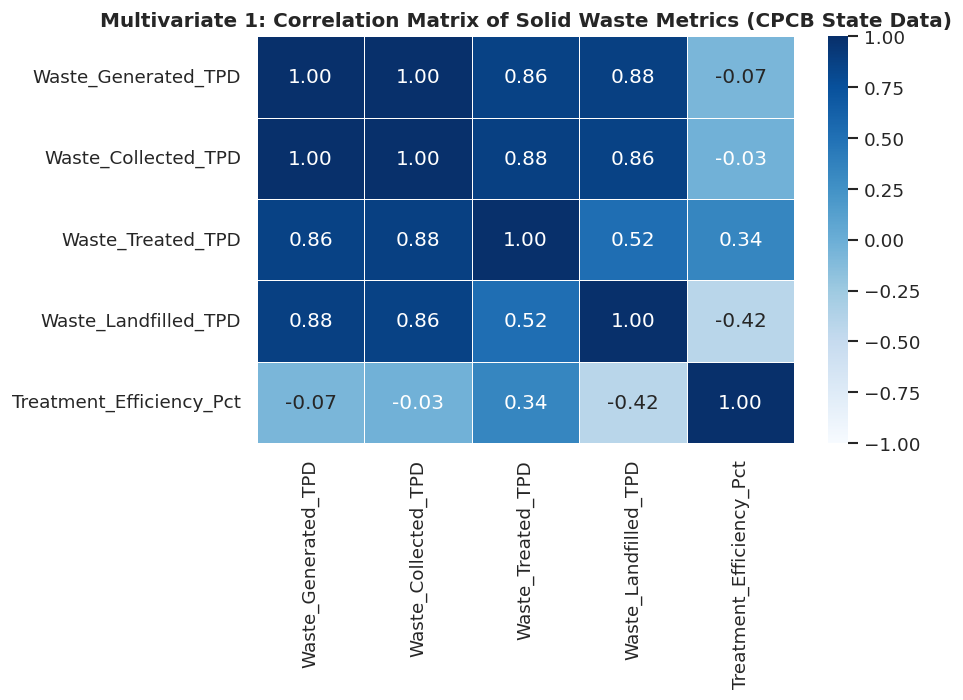

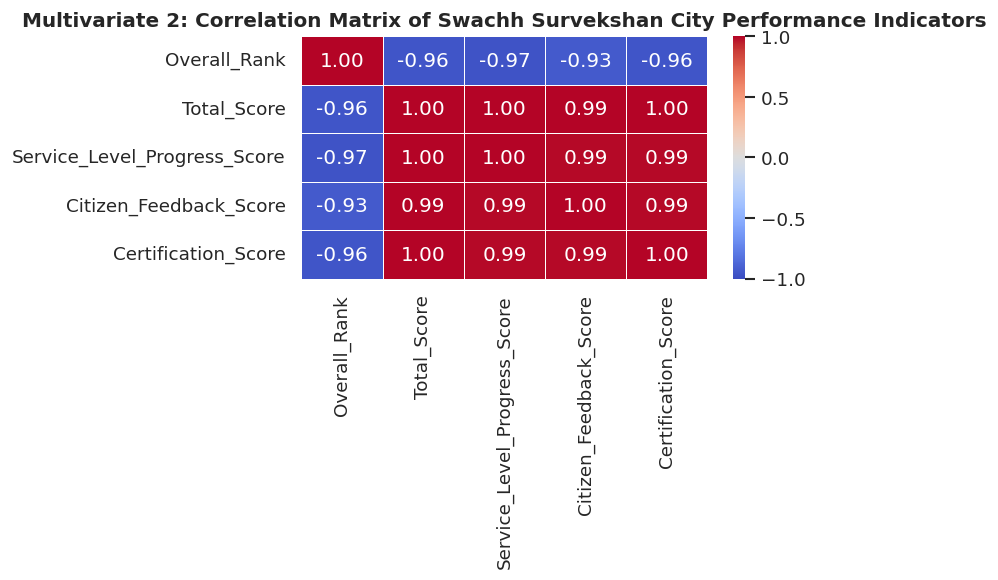

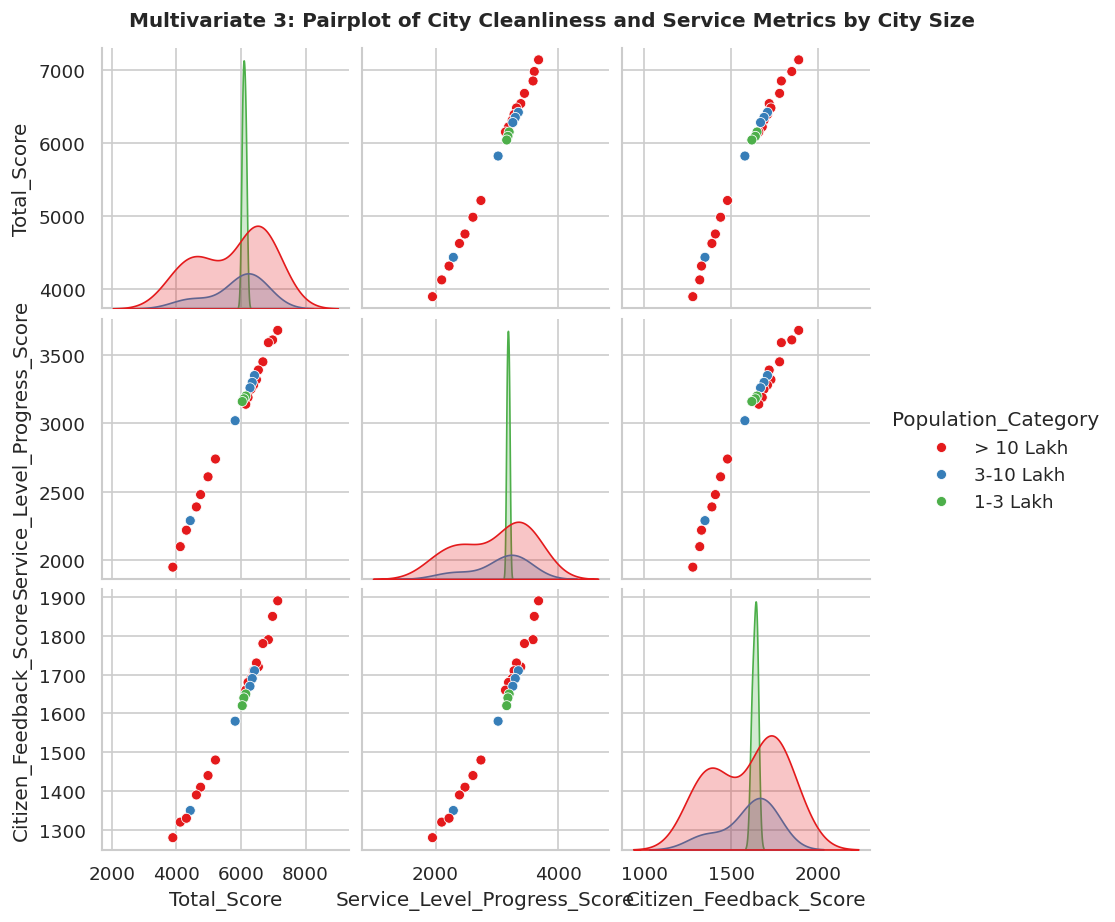

In [6]:
# ==============================================================================
# CELL 6: Multivariate Analysis (Heatmap & Pairplot)
# ==============================================================================

# Plot 8: Correlation Heatmap for State Dataset
plt.figure(figsize=(8, 6))
corr_cpcb = df_cpcb[['Waste_Generated_TPD', 'Waste_Collected_TPD', 'Waste_Treated_TPD',
                     'Waste_Landfilled_TPD', 'Treatment_Efficiency_Pct']].corr()
sns.heatmap(corr_cpcb, annot=True, cmap='Blues', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Multivariate 1: Correlation Matrix of Solid Waste Metrics (CPCB State Data)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 9: Correlation Heatmap for City Cleanliness Indicators
plt.figure(figsize=(7, 5))
corr_cities = df_cities[['Overall_Rank', 'Total_Score', 'Service_Level_Progress_Score',
                         'Citizen_Feedback_Score', 'Certification_Score']].corr()
sns.heatmap(corr_cities, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Multivariate 2: Correlation Matrix of Swachh Survekshan City Performance Indicators', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 10: Pairplot of Key City-Level Indicators by Population Tier
pair_cols = ['Total_Score', 'Service_Level_Progress_Score', 'Citizen_Feedback_Score', 'Population_Category']
sns.pairplot(df_cities[pair_cols], hue='Population_Category', palette='Set1', diag_kind='kde')
plt.suptitle('Multivariate 3: Pairplot of City Cleanliness and Service Metrics by City Size', y=1.02, fontsize=12, fontweight='bold')
plt.show()

In [7]:
# ==============================================================================
# CELL 7: Full Statistical Summary & Numerical Interpretation
# ==============================================================================
print("=== NUMERICAL DESCRIPTIVE STATISTICS (CPCB STATE DATA) ===")
desc_cpcb = df_cpcb[['Waste_Generated_TPD', 'Waste_Collected_TPD', 'Waste_Treated_TPD',
                     'Waste_Landfilled_TPD', 'Collection_Efficiency_Pct', 'Treatment_Efficiency_Pct']].describe()
print(desc_cpcb.round(2).to_string())

print("\n" + "="*70 + "\n")

print("=== NUMERICAL DESCRIPTIVE STATISTICS (CITY SWACHH SURVEKSHAN DATA) ===")
desc_cities = df_cities[['Total_Score', 'Service_Level_Progress_Score',
                         'Citizen_Feedback_Score', 'Certification_Score']].describe()
print(desc_cities.round(2).to_string())

=== NUMERICAL DESCRIPTIVE STATISTICS (CPCB STATE DATA) ===
       Waste_Generated_TPD  Waste_Collected_TPD  Waste_Treated_TPD  Waste_Landfilled_TPD  Collection_Efficiency_Pct  Treatment_Efficiency_Pct
count                63.00                63.00              63.00                 63.00                      63.00                     63.00
mean               7521.84              7087.78            3974.89               3112.89                      92.78                     53.95
std                5926.66              5787.45            3451.62               3190.19                       5.58                     19.87
min                 250.00               240.00             180.00                 35.00                      76.19                     11.11
25%                2925.00              2650.00            1325.00                775.00                      89.81                     38.74
50%                6424.00              5900.00            2900.00               2200.00 